# Step 9: Stacking ensemble

**Idea:** instead of trusting one model, let several different models each give a probability for every gas, then let a
small "meta-model" (logistic regression) learn how much to trust each of them.

**Rules fixed before looking at any test result**
- **Base models:** five different families: kNN, SVM, Random Forest, Gradient Boosting, Naive Bayes.
  (A single Decision Tree and AdaBoost are left out as near-copies of the tree ensembles.)
- **Settings:** the tuned settings from Step 8. For each family we use the reduction (none / PCA / LDA) with the best
  Step 8 *validation* score on batches 1-3, so nothing is chosen with test data.
- **No leakage:** the meta-model is trained on out-of-fold probabilities from **leave-one-batch-out** folds: the base
  models that predict batch *b* never saw batch *b*. Scalers, PCA, LDA and the base models are refitted inside every fold.
- **Comparisons:** each base model alone, a simple average of the base probabilities ("soft vote", no learning),
  and the learned stack.
- **Evaluation:** protocol A (train on batches 1-3, test on 4-10) is the headline. As supporting analysis, protocol C is
  run for test batches 4-10 only (batches 2 and 3 were used by Step 8 for validation). Protocol B needs at least two
  training batches for batch-wise folds, so it is not run.

The heavy computation is done by `scripts/run_step9_stacking.py` (it saves everything to `results/`); this notebook
loads those results, checks them and draws the graphs.

In [1]:
import os
import sys
import json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import stacking

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 90)

def read(name, **kw):
    # keep_default_na=False: otherwise pandas turns the text "None" (no reduction) into a missing value
    return pd.read_csv(f"../results/{name}", keep_default_na=False, **kw)

best = read("step8_best_params.csv")
configs = stacking.choose_base_configs(best)
val = best.set_index(["model", "reduction"])["mean_macro_f1"]
pd.DataFrame([{"base model": fam, "reduction": c["reduction"], "tuned settings": c["params"],
               "validation macro-F1 (Step 8)": val[(fam, c["reduction"])]} for fam, c in configs.items()])

,base model,reduction,tuned settings,validation macro-F1 (Step 8)
0,kNN,PCA,"{'n_neighbors': 1, 'weights': 'uniform'}",0.801
1,SVM,None,"{'C': 100, 'gamma': 0.01}",0.809
2,Random Forest,PCA,"{'n_estimators': 300, 'max_depth': 10, 'min_samples_leaf': 1, 'max_features': 'sqrt'}",0.813
3,Gradient Boosting,PCA,"{'n_estimators': 100, 'max_depth': 2}",0.802
4,Naive Bayes,PCA,{'var_smoothing': 0.001},0.737


## 1. Protocol A: fit the stack on batches 1-3, test on batches 4-10

In [2]:
m = pd.read_csv("../results/step9_stacking_metrics.csv")
A = m[m["protocol"] == "A"]
order = ["Stack (LR)", "Soft vote"] + list(configs)
pooledA = A[A["test_batch"] == "pooled"].set_index("model").loc[order]

step8 = read("step8_tuned_protocolA.csv")
ref = step8[step8["test_batch"] == "pooled"].set_index(["model", "reduction"])
best_single = ref["accuracy"].idxmax()
print("Best single tuned model in Step 8:", best_single, round(ref["accuracy"].max(), 3),
      "| macro-F1", round(ref.loc[best_single, "macro_f1"], 3))

tableA = pooledA[["accuracy", "macro_f1"]].round(3)
tableA.columns = ["pooled accuracy", "pooled macro-F1"]
tableA

Best single tuned model in Step 8: ('SVM', 'None') 0.732 | macro-F1 0.745


,pooled accuracy,pooled macro-F1
model,,
Stack (LR),0.702,0.710
Soft vote,0.753,0.754
kNN,0.649,0.663
SVM,0.732,0.745
Random Forest,0.695,0.672
Gradient Boosting,0.677,0.671
Naive Bayes,0.514,0.505


In [3]:
# consistency check: each base model alone must reproduce its Step 8 tuned result
rows = []
for fam, c in configs.items():
    r = ref.loc[(fam, c["reduction"])]
    rows.append({"base model": fam, "this step": pooledA.loc[fam, "accuracy"], "Step 8": r["accuracy"]})
chk = pd.DataFrame(rows).set_index("base model")
chk["difference"] = chk["this step"] - chk["Step 8"]
assert chk["difference"].abs().max() < 0.02, "a base model does not reproduce its Step 8 result:\n" + chk.to_string()
chk.round(4)

,this step,Step 8,difference
base model,,,
kNN,0.6490,0.6490,0.0
SVM,0.7319,0.7319,0.0
Random Forest,0.6953,0.6953,0.0
Gradient Boosting,0.6771,0.6771,0.0
Naive Bayes,0.5136,0.5136,0.0


In [4]:
perA = A[A["test_batch"] != "pooled"].copy()
perA["test_batch"] = perA["test_batch"].astype(int)
accA = perA.pivot(index="test_batch", columns="model", values="accuracy")[order]
print("Per-batch accuracy, protocol A")
accA.round(3)

Per-batch accuracy, protocol A


model,Stack (LR),Soft vote,kNN,SVM,Random Forest,Gradient Boosting,Naive Bayes
test_batch,,,,,,,
4,0.739,0.801,0.702,0.882,0.727,0.727,0.863
5,0.990,0.985,0.761,0.944,0.975,0.970,0.924
6,0.848,0.847,0.711,0.900,0.851,0.753,0.679
7,0.725,0.784,0.660,0.822,0.728,0.713,0.572
8,0.493,0.833,0.536,0.833,0.464,0.554,0.362
9,0.772,0.927,0.762,0.821,0.791,0.707,0.350
10,0.578,0.618,0.586,0.496,0.556,0.580,0.341


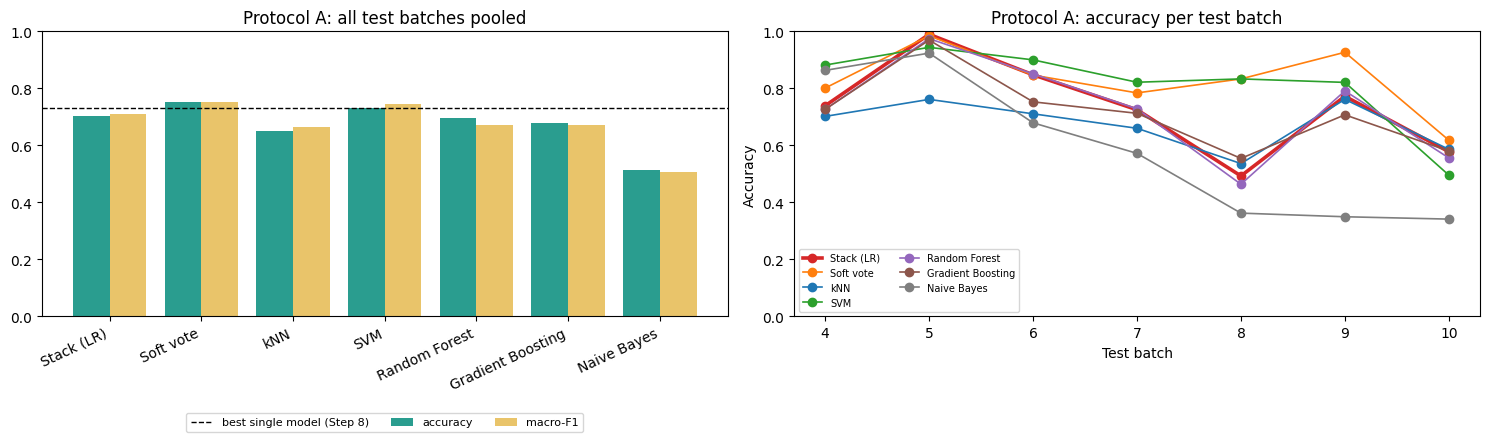

In [5]:
colors = dict(zip(order, ["#d62728", "#ff7f0e", "#1f77b4", "#2ca02c", "#9467bd", "#8c564b", "#7f7f7f"]))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
x = np.arange(len(order))
axes[0].bar(x - 0.2, pooledA["accuracy"], 0.4, label="accuracy", color="#2a9d8f")
axes[0].bar(x + 0.2, pooledA["macro_f1"], 0.4, label="macro-F1", color="#e9c46a")
axes[0].axhline(ref["accuracy"].max(), color="black", ls="--", lw=1, label="best single model (Step 8)")
axes[0].set_xticks(x); axes[0].set_xticklabels(order, rotation=25, ha="right")
axes[0].set_ylim(0, 1); axes[0].set_title("Protocol A: all test batches pooled")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=3, fontsize=8)
for n in order:
    axes[1].plot(accA.index, accA[n], marker="o", color=colors[n], label=n, lw=2.6 if n == "Stack (LR)" else 1.2)
axes[1].set_xlabel("Test batch"); axes[1].set_ylabel("Accuracy"); axes[1].set_ylim(0, 1)
axes[1].set_title("Protocol A: accuracy per test batch"); axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig("../results/step9_protocolA.png", dpi=150, bbox_inches="tight")
plt.show()

**What to notice (protocol A, pooled; single run, tuned settings):**

| | Pooled accuracy | Pooled macro-F1 |
|---|---|---|
| **Stack (learned meta-model)** | 70.2% | 71.0% |
| **Soft vote (plain average)** | **75.3%** | **75.4%** |
| SVM (best single model) | 73.2% | 74.5% |
| Random Forest + PCA | 69.5% | 67.2% |
| Gradient Boosting + PCA | 67.7% | 67.1% |
| kNN + PCA | 64.9% | 66.3% |
| Naive Bayes + PCA | 51.4% | 50.5% |

- **The learned stack did not beat the best single model:** 70.2% against SVM's 73.2%, a loss of 3.0 points.
- **The plain average did better than both:** 75.3% pooled accuracy, which is 2.1 points above SVM and 5.1 above the stack.
- **The per-batch picture is mixed.** The soft vote beats SVM on batches 5, 9 and 10, ties on batch 8 and loses on 4, 6 and 7.
  Its pooled advantage comes mostly from batch 10 (61.8% vs 49.6%, and batch 10 is a third of all test samples) and batch 9.
- **The stack is worst on batch 8:** 49.3%, against 83.3% for both SVM and the soft vote. It beats SVM only on batches 5 and 10.
- **Check passed:** every base model alone reproduces its Step 8 result exactly (differences of 0.0).

These are single runs without confidence intervals (Step 10), so a 2-point gap between the soft vote and SVM is
not yet conclusive.

## 2. What the meta-model learned

In [6]:
oof = pd.read_csv("../results/step9_oof_accuracy.csv", index_col=0)
oof["mean"] = oof.mean(axis=1)
print("Out-of-fold accuracy of each base model on the training batches (leave-one-batch-out):")
oof.round(3)

Out-of-fold accuracy of each base model on the training batches (leave-one-batch-out):


,batch 1 held out,batch 2 held out,batch 3 held out,mean
kNN,0.852,0.962,0.925,0.913
SVM,0.620,0.970,0.931,0.840
Random Forest,0.660,0.946,0.893,0.833
Gradient Boosting,0.639,0.943,0.931,0.838
Naive Bayes,0.515,0.850,0.914,0.759


Average absolute meta-model weight per base model (higher = trusted more):
kNN                  0.682
SVM                  1.223
Random Forest        0.903
Gradient Boosting    0.674
Naive Bayes          0.950


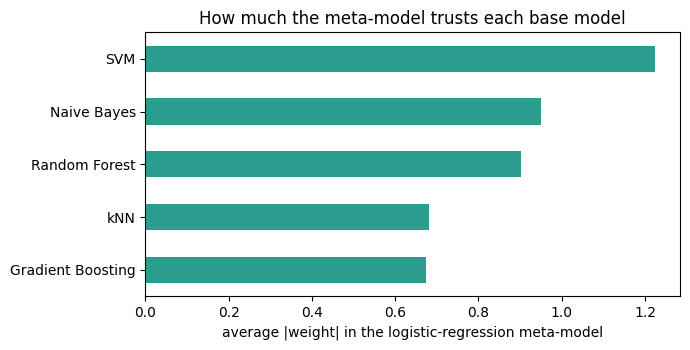

In [7]:
weights = pd.read_csv("../results/step9_meta_weights.csv", index_col=0)["mean_abs_weight"]
print("Average absolute meta-model weight per base model (higher = trusted more):")
print(weights.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 3.6))
weights.sort_values().plot(kind="barh", color="#2a9d8f", ax=ax)
ax.set_xlabel("average |weight| in the logistic-regression meta-model")
ax.set_title("How much the meta-model trusts each base model")
plt.tight_layout()
plt.savefig("../results/step9_meta_weights.png", dpi=150)
plt.show()

**What to notice:**
- **The meta-model learned from data where the base models look good.** On the training batches (each batch predicted by
  models trained on the other two), the base models score 76-91% on average. But it is much easier to predict batches 2
  and 3 (85-97%) than batch 1 (52-85%), and all of this is *near in time* to the training data.
- **Largest weights:** SVM (1.22), Naive Bayes (0.95) and Random Forest (0.90); kNN and Gradient Boosting get about 0.67.
  The weights are a rough guide only, because the models' probabilities are on different scales.
- **A plausible reason the stack does worse than a plain average on later batches** is that its training data never
  shows it how badly the models fail far from the training period, so it cannot learn to hedge. A plain average does not
  depend on that. We did not test this explanation directly.

## 3. Protocol C (test batches 4-10): retrain on all earlier batches every time

In [8]:
C = m[m["protocol"] == "C"]
accC = C.assign(test_batch=C["test_batch"].astype(int)).pivot(
    index="test_batch", columns="model", values="accuracy")[order]
print("Protocol C accuracy per test batch")
accC.round(3)

Protocol C accuracy per test batch

model,Stack (LR),Soft vote,kNN,SVM,Random Forest,Gradient Boosting,Naive Bayes
test_batch,,,,,,,
4,0.739,0.801,0.702,0.882,0.727,0.727,0.863
5,0.980,0.985,0.797,0.964,0.985,0.980,0.924
6,0.948,0.896,0.832,0.890,0.825,0.876,0.525
7,0.877,0.865,0.828,0.859,0.865,0.839,0.527
8,0.884,0.721,0.859,0.909,0.511,0.591,0.402
9,0.989,0.989,0.992,0.989,0.967,0.959,0.593
10,0.669,0.713,0.642,0.704,0.659,0.650,0.419


In [9]:
summaryC = pd.DataFrame({"mean accuracy": accC.mean(), "worst batch": accC.min()})
summaryC.round(3)

,mean accuracy,worst batch
model,,
Stack (LR),0.870,0.669
Soft vote,0.853,0.713
kNN,0.807,0.642
SVM,0.886,0.704
Random Forest,0.791,0.511
Gradient Boosting,0.803,0.591
Naive Bayes,0.608,0.402


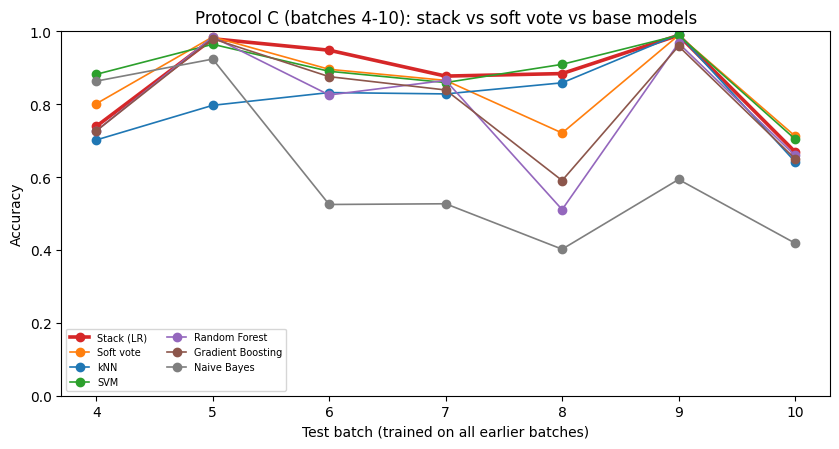

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for n in order:
    ax.plot(accC.index, accC[n], marker="o", color=colors[n], label=n, lw=2.6 if n == "Stack (LR)" else 1.2)
ax.set_xlabel("Test batch (trained on all earlier batches)"); ax.set_ylabel("Accuracy"); ax.set_ylim(0, 1)
ax.set_title("Protocol C (batches 4-10): stack vs soft vote vs base models"); ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig("../results/step9_protocolC.png", dpi=150)
plt.show()

**What to notice (protocol C, test batches 4-10; each model is retrained on all earlier batches):**

| | Mean accuracy | Worst batch |
|---|---|---|
| SVM | **88.6%** | 70.4% |
| **Stack (LR)** | 87.0% | 66.9% |
| Soft vote | 85.3% | 71.3% |
| kNN + PCA | 80.7% | 64.2% |
| Gradient Boosting + PCA | 80.3% | 59.1% |
| Random Forest + PCA | 79.1% | 51.1% |
| Naive Bayes + PCA | 60.8% | 40.2% |

- **With plenty of recent labelled data the stack is competitive:** it is second best on average and the best on batches
  6 (94.8%) and 7 (87.7%). But **SVM alone is still best on average** (88.6% vs 87.0%).
- **The soft vote is no longer ahead** (85.3%), which is the opposite of protocol A. So there is no consistent winner
  between the stack and the soft vote across the two protocols.
- Batch 4 here uses the same training batches as protocol A (1-3), so its numbers are identical to protocol A's batch 4.

## Summary of Step 9
- A stacking ensemble of five different models (kNN, SVM, Random Forest, Gradient Boosting, Naive Bayes), with tuned
  settings and a logistic-regression meta-model trained on leave-one-batch-out predictions, was built and tested.
- **The learned stack did not beat the best single model** on protocol A (70.2% vs SVM 73.2%) or on protocol C (mean 87.0%
  vs 88.6%). This is a valid negative result and is reported as it is.
- **A plain average of the same models (soft vote) was the best on protocol A** (75.3%), but not on protocol C (85.3%).
  The gain on A comes mainly from batches 9 and 10.
- A bug found on the way (the base models' labels were shifted by one inside scikit-learn's stacking class) was fixed
  and is now covered by a regression test; the consistency check against Step 8 passes exactly.
- Limits: single runs, no confidence intervals yet (Step 10), five base models with one meta-model, tuned settings from
  only two validation folds, and protocol B not applicable.